# Assignment 6: Model Compression and Optimization

## Introduction

In this assignment I build a convolutional neural network (CNN) that classifies small colour images from the CIFAR-10 dataset into 10 categories: aeroplane, car, bird, cat, deer, dog, frog, horse, ship and truck. The goal for this baseline model is at least 75% accuracy on the test set.

After training the baseline, I apply two model compression techniques, pruning and quantization, to make the model smaller and faster. For each version I measure accuracy, model size in megabytes and inference latency in milliseconds, so I can see what each technique gains and what it costs. This reflects a real deployment problem: a model that is accurate on a powerful computer may be too large or too slow for a phone or another small device.

I use PyTorch for this work and train the models on my computer's NVIDIA graphics card.

## Part 1: Load and Explore the CIFAR-10 Data

In [1]:
# I import the libraries I need for the whole assignment
import os
import time
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, random_split

In [2]:
# I fix the random seed so my results are the same every time I run the notebook
torch.manual_seed(42)
np.random.seed(42)

In [3]:
# I choose the graphics card (GPU) if PyTorch can see it, otherwise the processor (CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version:", torch.__version__)
print("Training device:", device)
if device.type == "cuda":
    print("GPU name:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu128
Training device: cuda
GPU name: NVIDIA GeForce RTX 5060 Laptop GPU


In [4]:
# The average and spread of each colour channel (red, green, blue) across CIFAR-10
# These are standard published values for this dataset
cifar_mean = (0.4914, 0.4822, 0.4465)
cifar_std = (0.2470, 0.2435, 0.2616)

In [5]:
# Training images: I add small random changes so the model sees more variety
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),   # shift the image a little in a random direction
    transforms.RandomHorizontalFlip(),      # flip left-to-right half of the time
    transforms.ToTensor(),                  # turn the image into numbers between 0 and 1
    transforms.Normalize(cifar_mean, cifar_std)  # standardize each colour channel
])

In [6]:
# Validation and test images: no random changes, only the same conversion and standardizing
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(cifar_mean, cifar_std)
])

In [7]:
# I download CIFAR-10 into a folder called "data" (only the first time)
# I load the 50,000 training images twice: once with the random changes, once without
full_train_aug = torchvision.datasets.CIFAR10(root="./data", train=True, download=True, transform=train_transform)
full_train_plain = torchvision.datasets.CIFAR10(root="./data", train=True, download=False, transform=test_transform)
test_set = torchvision.datasets.CIFAR10(root="./data", train=False, download=True, transform=test_transform)

C:\Users\patel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


In [8]:
# I shuffle the 50,000 image positions with a fixed seed and split them: 45,000 for training, 5,000 for validation
shuffled = torch.randperm(50000, generator=torch.Generator().manual_seed(42)).tolist()
train_idx, val_idx = shuffled[:45000], shuffled[45000:]

In [9]:
# Training uses the version with random changes; validation uses the clean version
train_set = torch.utils.data.Subset(full_train_aug, train_idx)
val_set = torch.utils.data.Subset(full_train_plain, val_idx)

In [10]:
# I create loaders that feed the images to the model in batches of 128
batch_size = 128
train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, num_workers=0, pin_memory=True)
val_loader = DataLoader(val_set, batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=True)
test_loader = DataLoader(test_set, batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=True)

In [11]:
# The names of the 10 classes, in label order 0 to 9
class_names = test_set.classes

In [12]:
print("Training images:  ", len(train_set))
print("Validation images:", len(val_set))
print("Test images:      ", len(test_set))
print("Classes:", class_names)

# I take one batch to check its shape
images, labels = next(iter(train_loader))
print("\nOne batch of images:", images.shape)
print("One batch of labels:", labels.shape)

Training images:   45000
Validation images: 5000
Test images:       10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

One batch of images: torch.Size([128, 3, 32, 32])
One batch of labels: torch.Size([128])


**Interpretation**

I downloaded the official CIFAR-10 dataset through torchvision. It comes already divided into 50,000 training images and 10,000 test images. I then split the 50,000 training images into 45,000 for training and 5,000 for validation, using a fixed random seed so the split is the same every time I run the notebook. The model learns from the training images, I use the validation images to follow its progress after every epoch, and the 10,000 test images stay hidden until the final evaluation.

There are 10 classes: airplane, automobile, bird, cat, deer, dog, frog, horse, ship and truck. CIFAR-10 has the same number of images in every class, so unlike the wine data in Assignment 4, this dataset is balanced.

I prepared the images in two different ways. For training, each image is randomly shifted a little and flipped left to right half of the time. This is data augmentation: the model sees slightly different versions of each image in every epoch, which helps it learn the object itself instead of memorising exact pixels. For validation and testing, I do not change the images, so the model is always measured on the real pictures. In both cases the pixel values are converted to numbers between 0 and 1 and then standardized with the mean and standard deviation of each colour channel.

The images are fed to the model in batches of 128. The shape of one batch is 128 × 3 × 32 × 32, which means 128 images, each with 3 colour channels (red, green and blue) and a size of 32 by 32 pixels. The labels batch holds 128 numbers, one class label for each image.

In [13]:
# I check the published mean and std by calculating them myself from the 50,000 training images
# .data holds the raw images as numbers from 0 to 255, shape (50000, 32, 32, 3)
raw_pixels = full_train_aug.data / 255.0

In [14]:
# I calculate one mean and one std per colour channel, across all images and all pixel positions
my_mean = raw_pixels.mean(axis=(0, 1, 2))
my_std = raw_pixels.std(axis=(0, 1, 2))

In [15]:
print("Raw data shape:", full_train_aug.data.shape)
print("My mean (R, G, B):       ", np.round(my_mean, 4))
print("Published mean (R, G, B):", cifar_mean)
print("My std (R, G, B):        ", np.round(my_std, 4))
print("Published std (R, G, B): ", cifar_std)

Raw data shape: (50000, 32, 32, 3)
My mean (R, G, B):        [0.4914 0.4822 0.4465]
Published mean (R, G, B): (0.4914, 0.4822, 0.4465)
My std (R, G, B):         [0.247  0.2435 0.2616]
Published std (R, G, B):  (0.247, 0.2435, 0.2616)


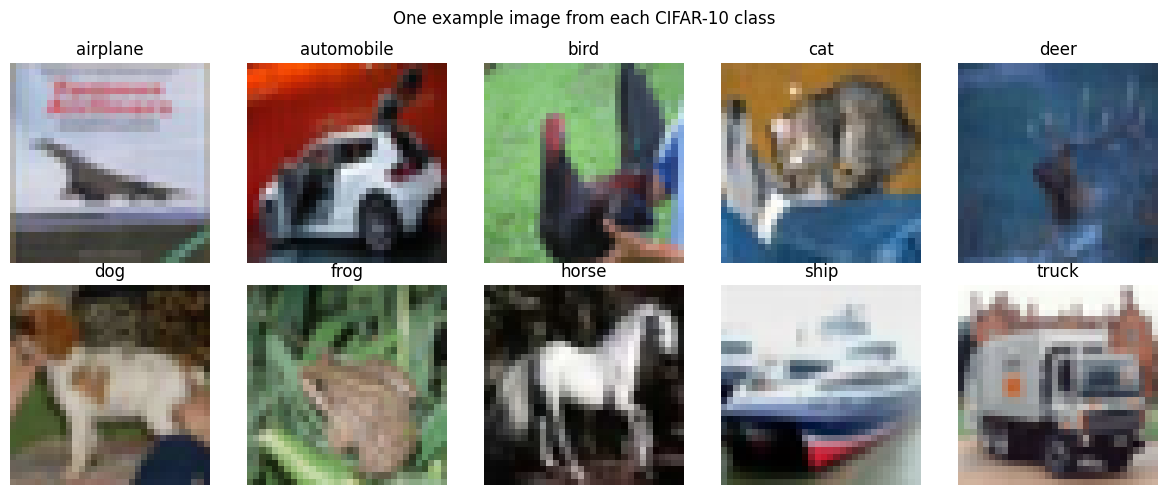

In [16]:
# I show one example image from each of the 10 classes
# I use the raw test images (.data) so the colours look natural, without standardizing
raw_images = test_set.data            # shape (10000, 32, 32, 3), values 0 to 255
raw_labels = np.array(test_set.targets)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for class_id, ax in enumerate(axes.flat):
    # I find the first image that belongs to this class
    first_index = np.where(raw_labels == class_id)[0][0]
    ax.imshow(raw_images[first_index])
    ax.set_title(class_names[class_id])
    ax.axis("off")

plt.suptitle("One example image from each CIFAR-10 class")
plt.tight_layout()
plt.show()

**Interpretation**

The grid shows one example image from each of the 10 classes. The images are very small, only 32 by 32 pixels, so they look blurry and many details are lost. In some of them it is not easy even for a person to see what the object is.

This shows why CIFAR-10 is a harder problem than the tabular datasets I used before. The model does not get clear features like alcohol level or house size. It only gets 3,072 pixel values per image and has to learn by itself which patterns of colour and shape belong to each class. Some classes also look alike at this size, such as cat and dog, deer and horse, or automobile and truck, so I expect the model to confuse these pairs more than others.

## Part 2: Baseline CNN Model

In [17]:
# I build my CNN from repeated blocks: convolution -> batch normalization -> ReLU
def conv_block(in_channels, out_channels):
    return [
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU()
    ]

In [18]:
# I build my CNN from repeated blocks: convolution -> batch normalization -> ReLU
def conv_block(in_channels, out_channels):
    return [
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU()
    ]

class BaselineCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        # Feature part: three stages, each with two blocks, then pooling to halve the image size
        self.features = nn.Sequential(
            *conv_block(3, 32), *conv_block(32, 32),
            nn.MaxPool2d(2), nn.Dropout(0.1),      # 32x32 -> 16x16
            *conv_block(32, 64), *conv_block(64, 64),
            nn.MaxPool2d(2), nn.Dropout(0.2),      # 16x16 -> 8x8
            *conv_block(64, 128), *conv_block(128, 128),
            nn.MaxPool2d(2), nn.Dropout(0.3)       # 8x8 -> 4x4
        )
        # Decision part: turn the features into a score for each of the 10 classes
        self.classifier = nn.Sequential(
            nn.Flatten(),                          # 128 x 4 x 4 = 2,048 numbers in one row
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        # The path an image takes through the model
        x = self.features(x)
        x = self.classifier(x)
        return x

# I create the model and move it to the graphics card
baseline_model = BaselineCNN().to(device)
print(baseline_model)

# I count how many weights (parameters) the model has to learn
total_params = sum(p.numel() for p in baseline_model.parameters())
print(f"\nTotal parameters: {total_params:,}")

BaselineCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout(p=0.1, inplace=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (12): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (13): ReLU()
    (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (15): Dropout(p=0.2, inpla

**Interpretation**

My baseline model is a convolutional neural network with two parts. The feature part has three stages. Each stage has two convolution blocks, and each block is a convolution layer followed by batch normalization and a ReLU activation. After each stage, max pooling halves the width and height of the image (from 32 × 32 to 16 × 16, then 8 × 8, then 4 × 4) and dropout switches off a share of the values during training to reduce overfitting. The number of filters grows from 32 to 64 to 128, so the model can learn simple patterns like edges in the early layers and more complex shapes in the later layers.

The classifier part flattens the final 128 × 4 × 4 block of features into one row of 2,048 numbers, passes it through a fully connected layer of 256 units, and ends with a layer of 10 outputs, one score for each class.

The model has 815,018 parameters in total. Almost two thirds of them, 524,544, are in the first fully connected layer, which connects 2,048 inputs to 256 outputs. The six convolution layers together have only about 287,000. This shows that the size of a model is not spread evenly, and it tells me where compression can save the most space later.

In [19]:
# I train the model for one full pass over the training data (one epoch)
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()                       # training mode: dropout is switched on
    total_loss, correct, total = 0.0, 0, 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()           # clear the corrections from the previous batch
        outputs = model(images)         # the model makes its predictions (10 scores per image)
        loss = criterion(outputs, labels)   # how wrong the predictions are
        loss.backward()                 # work out how each weight should change
        optimizer.step()                # change the weights a little in that direction

        total_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total * 100

In [20]:
# I measure the model on data it does not learn from (validation or test)
def evaluate(model, loader, criterion, device):
    model.eval()                        # evaluation mode: dropout is switched off
    total_loss, correct, total = 0.0, 0, 0

    with torch.no_grad():               # no learning here, so I skip the gradient calculations
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, correct / total * 100

In [21]:
# I set up the training
num_epochs = 30
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(baseline_model.parameters(), lr=0.001, weight_decay=5e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)

In [22]:
# I keep a record of every epoch so I can draw the training curves later
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_val_acc = 0.0
best_weights = None

start_time = time.time()
for epoch in range(1, num_epochs + 1):
    epoch_start = time.time()

    train_loss, train_acc = train_one_epoch(baseline_model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = evaluate(baseline_model, val_loader, criterion, device)
    scheduler.step()      # lower the learning rate a little for the next epoch

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    # I keep a copy of the weights from the epoch with the best validation accuracy
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_weights = copy.deepcopy(baseline_model.state_dict())

    print(f"Epoch {epoch:2d}/{num_epochs} | "
          f"train loss {train_loss:.3f}, acc {train_acc:.1f}% | "
          f"val loss {val_loss:.3f}, acc {val_acc:.1f}% | "
          f"{time.time() - epoch_start:.0f}s")

print(f"\nTotal training time: {(time.time() - start_time) / 60:.1f} minutes")
print(f"Best validation accuracy: {best_val_acc:.2f}%")

# I load the best weights back into the model and save them to a file
baseline_model.load_state_dict(best_weights)
torch.save(baseline_model.state_dict(), "baseline_cnn.pth")
print("Saved the best baseline model as baseline_cnn.pth")

Epoch  1/30 | train loss 1.584, acc 41.4% | val loss 1.343, acc 52.4% | 10s
Epoch  2/30 | train loss 1.182, acc 57.6% | val loss 1.015, acc 63.5% | 9s
Epoch  3/30 | train loss 1.020, acc 64.0% | val loss 0.980, acc 65.4% | 10s
Epoch  4/30 | train loss 0.923, acc 67.7% | val loss 0.808, acc 71.9% | 10s
Epoch  5/30 | train loss 0.860, acc 70.1% | val loss 0.759, acc 72.2% | 11s
Epoch  6/30 | train loss 0.807, acc 72.1% | val loss 0.630, acc 77.6% | 11s
Epoch  7/30 | train loss 0.760, acc 74.0% | val loss 0.665, acc 76.2% | 11s
Epoch  8/30 | train loss 0.716, acc 75.4% | val loss 0.610, acc 78.8% | 11s
Epoch  9/30 | train loss 0.686, acc 76.6% | val loss 0.671, acc 76.8% | 11s
Epoch 10/30 | train loss 0.651, acc 77.6% | val loss 0.567, acc 80.3% | 11s
Epoch 11/30 | train loss 0.624, acc 78.9% | val loss 0.542, acc 80.9% | 11s
Epoch 12/30 | train loss 0.606, acc 79.4% | val loss 0.530, acc 81.7% | 11s
Epoch 13/30 | train loss 0.581, acc 80.1% | val loss 0.534, acc 81.5% | 11s
Epoch 14/30 |

**Interpretation**

I trained the baseline model for 30 epochs. Each epoch took about 11 seconds on the graphics card, so the full training took 5.4 minutes. The best validation accuracy was 87.46%, and I saved the weights from that epoch as baseline_cnn.pth.

Both the training loss and the validation loss went down steadily, and in the final epochs the numbers changed very little, which shows that the model had mostly finished learning. The learning rate schedule helped here: it started with larger steps to learn quickly and ended with very small steps to fine-tune.

The validation accuracy was a little higher than the training accuracy throughout training. This is expected with my set-up. During training the images are randomly shifted and flipped and dropout switches off part of the network, which makes the task harder. During validation the images are unchanged and dropout is off. Because the validation results stayed as good as or better than the training results, there is no sign of overfitting: the model is learning general patterns rather than memorising the training images.

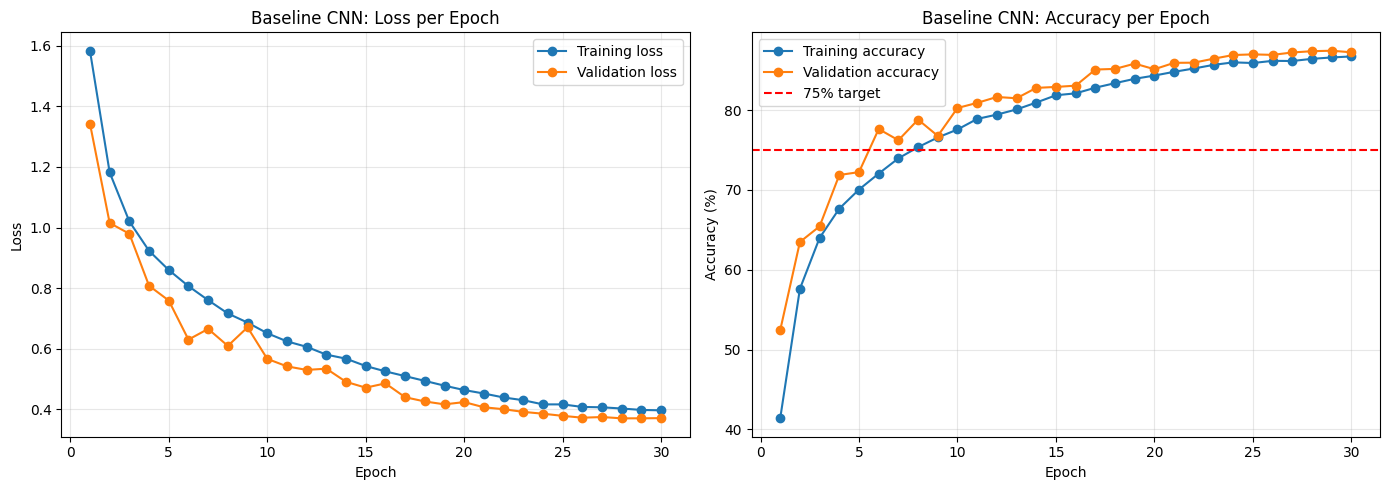

In [23]:
# I draw the loss and accuracy for every epoch, for training and validation
epochs = range(1, num_epochs + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left chart: loss
ax1.plot(epochs, history["train_loss"], marker="o", label="Training loss")
ax1.plot(epochs, history["val_loss"], marker="o", label="Validation loss")
ax1.set_title("Baseline CNN: Loss per Epoch")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Right chart: accuracy, with a line at the 75% target
ax2.plot(epochs, history["train_acc"], marker="o", label="Training accuracy")
ax2.plot(epochs, history["val_acc"], marker="o", label="Validation accuracy")
ax2.axhline(75, color="red", linestyle="--", label="75% target")
ax2.set_title("Baseline CNN: Accuracy per Epoch")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy (%)")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("baseline_training_curves.png", dpi=150)   # I save the chart for my report
plt.show()

**Interpretation**

The left chart shows the loss for every epoch. Both lines fall steeply in the first few epochs and then flatten out. The validation line stays slightly below the training line and the two lines never move apart, which means the model did not overfit.

The right chart shows the accuracy. Both lines rise quickly at the start and level off in the high 80s, well above the red 75% target line. The curves are almost flat in the last epochs, so training for more epochs with this set-up would probably add very little.

## Part 3: Baseline Evaluation on the Test Set

In [24]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# I collect the true labels and the model's predictions for every test image
def get_predictions(model, loader, device):
    model.eval()
    all_labels, all_preds = [], []
    with torch.no_grad():
        for images, labels in loader:
            outputs = model(images.to(device))
            all_preds.append(outputs.argmax(dim=1).cpu())
            all_labels.append(labels)
    return torch.cat(all_labels).numpy(), torch.cat(all_preds).numpy()

# I measure the baseline on the 10,000 test images it has never seen
baseline_test_loss, baseline_test_acc = evaluate(baseline_model, test_loader, criterion, device)
print(f"Baseline test loss:     {baseline_test_loss:.3f}")
print(f"Baseline test accuracy: {baseline_test_acc:.2f}%")

y_true, y_pred_baseline = get_predictions(baseline_model, test_loader, device)

# Precision, recall and F1 for each class
print("\nClassification report:")
print(classification_report(y_true, y_pred_baseline, target_names=class_names, digits=3))


Baseline test loss:     0.386
Baseline test accuracy: 86.99%

Classification report:
              precision    recall  f1-score   support

    airplane      0.880     0.877     0.878      1000
  automobile      0.951     0.937     0.944      1000
        bird      0.844     0.779     0.810      1000
         cat      0.803     0.696     0.746      1000
        deer      0.823     0.882     0.851      1000
         dog      0.797     0.803     0.800      1000
        frog      0.862     0.943     0.901      1000
       horse      0.901     0.904     0.903      1000
        ship      0.912     0.949     0.930      1000
       truck      0.918     0.929     0.923      1000

    accuracy                          0.870     10000
   macro avg      0.869     0.870     0.869     10000
weighted avg      0.869     0.870     0.869     10000



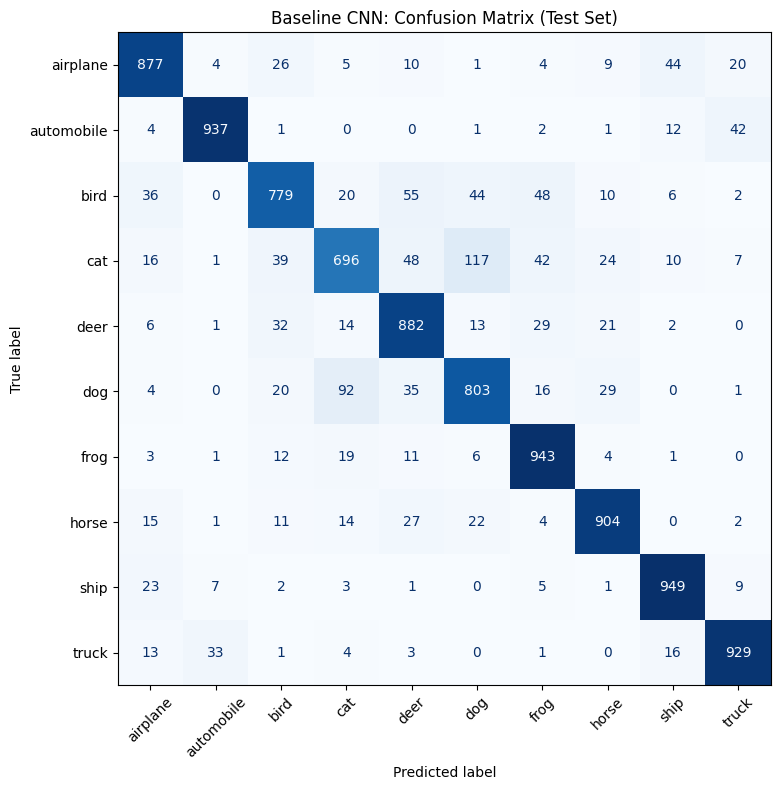

In [25]:
# Confusion matrix: rows are the true classes, columns are the predicted classes
cm = confusion_matrix(y_true, y_pred_baseline)
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
ax.set_title("Baseline CNN: Confusion Matrix (Test Set)")
plt.tight_layout()
plt.savefig("baseline_confusion_matrix.png", dpi=150)
plt.show()

**Interpretation**

On the 10,000 test images, which the model had never seen, the baseline reached an accuracy of 86.99% with a test loss of 0.386. This is close to the best validation accuracy of 87.46%, which shows that the model generalises well to new images. The result is well above the 75% target.

The classification report shows that performance differs between classes. Vehicles and clear shapes are the easiest: automobile has the best F1-score at 0.944, followed by ship at 0.930 and truck at 0.923. Animals are harder. Cat is clearly the weakest class, with a recall of only 0.696, which means the model missed about 30% of the cats in the test set. Dog (F1 0.800) and bird (F1 0.810) are also below the other classes.

The confusion matrix shows where the mistakes come from, and they follow the pattern I expected from the sample images. The largest confusion is between cats and dogs, which the model often mixes up in both directions. Other similar-looking pairs, such as automobile and truck, and airplane and ship, are also confused more than other classes. These mistakes make sense, because at 32 × 32 pixels these objects have similar sizes, shapes and colours.

Because the classes are balanced, the macro average and the weighted average are the same: 0.869 for precision and F1, and 0.870 for recall. This baseline is the reference point I will compare the compressed models against.

In [26]:
# I measure the size of a model by saving its weights to a file and checking the file size
def get_model_size_mb(model, filename):
    torch.save(model.state_dict(), filename)
    return os.path.getsize(filename) / (1024 * 1024)

In [27]:
# I measure latency: the average time to classify ONE image, in milliseconds
def measure_latency(model, device, num_images=500, warmup=20):
    model = model.to(device)
    model.eval()
    # I take a fixed sample of test images, one at a time (batch size 1)
    samples = [test_set[i][0].unsqueeze(0) for i in range(num_images)]
    times = []
    with torch.no_grad():
        # Warm-up: the first few runs are slower while the device gets ready, so I don't time them
        for img in samples[:warmup]:
            model(img.to(device))
        for img in samples:
            img = img.to(device)
            if device.type == "cuda":
                torch.cuda.synchronize()          # make sure the GPU has finished earlier work
            start = time.perf_counter()
            model(img)
            if device.type == "cuda":
                torch.cuda.synchronize()          # wait until the GPU has really finished this image
            times.append((time.perf_counter() - start) * 1000)
    return np.mean(times)

cpu = torch.device("cpu")

baseline_size = get_model_size_mb(baseline_model, "baseline_cnn.pth")
baseline_latency_gpu = measure_latency(baseline_model, device)
baseline_latency_cpu = measure_latency(copy.deepcopy(baseline_model), cpu)

In [28]:
print(f"Baseline parameters:   {total_params:,}")
print(f"Baseline model size:   {baseline_size:.2f} MB")
print(f"Latency on GPU:        {baseline_latency_gpu:.2f} ms per image")
print(f"Latency on CPU:        {baseline_latency_cpu:.2f} ms per image")


Baseline parameters:   815,018
Baseline model size:   3.13 MB
Latency on GPU:        0.84 ms per image
Latency on CPU:        0.62 ms per image


In [29]:
# I start a results list that will hold one row per model, for the final comparison
results = [{
    "Model": "Baseline",
    "Test accuracy (%)": round(baseline_test_acc, 2),
    "Size (MB)": round(baseline_size, 2),
    "CPU latency (ms)": round(baseline_latency_cpu, 2),
}]

**Interpretation**

The baseline model has 815,018 parameters and its saved file is 3.13 MB. Each parameter is stored as a 32-bit floating-point number, which takes 4 bytes, so 815,018 parameters take about 3.1 MB. This is the size that the compression techniques will try to reduce.

I measured latency as the average time to classify one image, using 500 test images one at a time after a short warm-up. The model took [GPU ms] milliseconds per image on the graphics card and 0.62 milliseconds per image on the processor. For one small 32 × 32 image the processor is very fast, because the graphics card is designed for large amounts of parallel work and spends much of its time on fixed overhead, such as copying the image to the card and starting the calculation. The graphics card is still much faster for training, where it processes 128 images at a time.

For the rest of the assignment I compare all models using CPU latency. Quantized models in PyTorch run only on the processor, so this keeps the comparison fair. It is also realistic, because compressed models are usually deployed on phones and small devices that do not have a powerful graphics card.

## Part 4: Pruning

In [30]:
import torch.nn.utils.prune as prune

# I prune the smallest weights across all convolution and linear layers together
def apply_global_pruning(model, amount):
    layers_to_prune = [(m, "weight") for m in model.modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
    prune.global_unstructured(layers_to_prune, pruning_method=prune.L1Unstructured, amount=amount)
    return layers_to_prune

# I calculate what share of the convolution and linear weights are exactly zero
def weight_sparsity(model):
    zeros, total = 0, 0
    for m in model.modules():
        if isinstance(m, (nn.Conv2d, nn.Linear)):
            zeros += (m.weight == 0).sum().item()
            total += m.weight.numel()
    return zeros / total * 100

In [31]:
# I try several pruning levels on copies of the baseline, with no fine-tuning
sensitivity = []
for amount in [0.3, 0.5, 0.7, 0.8, 0.9]:
    test_model = copy.deepcopy(baseline_model)
    apply_global_pruning(test_model, amount)
    _, val_acc = evaluate(test_model, val_loader, criterion, device)
    sensitivity.append({
        "Pruned (%)": int(amount * 100),
        "Sparsity (%)": round(weight_sparsity(test_model), 1),
        "Val accuracy (%)": round(val_acc, 2),
        "Drop vs baseline": round(val_acc - best_val_acc, 2)
    })

sensitivity_df = pd.DataFrame(sensitivity)
print(f"Baseline validation accuracy: {best_val_acc:.2f}%\n")
print(sensitivity_df.to_string(index=False))

Baseline validation accuracy: 87.46%

 Pruned (%)  Sparsity (%)  Val accuracy (%)  Drop vs baseline
         30          30.0             87.48              0.02
         50          50.0             86.86             -0.60
         70          70.0             83.30             -4.16
         80          80.0             54.90            -32.56
         90          90.0              9.96            -77.50


**Interpretation**

Before fine-tuning, I tested how much of the model I could prune. I applied global L1 pruning at five levels to separate copies of the baseline and measured each copy on the validation set. I used the validation set and not the test set because I am using these results to choose a pruning level, and the test set must stay unused until the final evaluation.

The model handled moderate pruning very well. Removing 30% of the weights did not reduce the validation accuracy at all (87.48% against 87.46%), and removing 50% reduced it by only 0.60 points. This shows that a large share of the weights in my baseline were very small and contributed almost nothing to its predictions. At 70% the drop became noticeable at 4.16 points, but the accuracy of 83.30% was still well above the 75% target.

After that, the accuracy collapsed. At 80% pruning it fell to 54.90%, and at 90% it fell to 9.96%, which is the same as a model guessing randomly among 10 classes. At these levels the pruning removes weights the model really needs, and without retraining the remaining weights cannot compensate. The point between 70% and 80% is where the model starts to break.

In [32]:
# I make a fresh copy of the baseline and prune 80% of its weights
prune_amount = 0.8
pruned_model = copy.deepcopy(baseline_model)
pruned_layers = apply_global_pruning(pruned_model, prune_amount)

_, val_acc_before = evaluate(pruned_model, val_loader, criterion, device)
print(f"Sparsity after pruning: {weight_sparsity(pruned_model):.1f}%")
print(f"Validation accuracy before fine-tuning: {val_acc_before:.2f}%\n")

Sparsity after pruning: 80.0%
Validation accuracy before fine-tuning: 54.90%



In [33]:
# I fine-tune: train for a few more epochs with a smaller learning rate
# The pruning masks stay in place, so the removed weights stay at zero the whole time
ft_epochs = 10
ft_optimizer = torch.optim.AdamW(pruned_model.parameters(), lr=0.0005, weight_decay=5e-4)
ft_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(ft_optimizer, T_max=ft_epochs)

prune_history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_pruned_val_acc = 0.0
best_pruned_weights = None

for epoch in range(1, ft_epochs + 1):
    train_loss, train_acc = train_one_epoch(pruned_model, train_loader, criterion, ft_optimizer, device)
    val_loss, val_acc = evaluate(pruned_model, val_loader, criterion, device)
    ft_scheduler.step()

    prune_history["train_loss"].append(train_loss)
    prune_history["train_acc"].append(train_acc)
    prune_history["val_loss"].append(val_loss)
    prune_history["val_acc"].append(val_acc)

    if val_acc > best_pruned_val_acc:
        best_pruned_val_acc = val_acc
        best_pruned_weights = copy.deepcopy(pruned_model.state_dict())

    print(f"Fine-tune epoch {epoch:2d}/{ft_epochs} | train acc {train_acc:.1f}% | "
          f"val loss {val_loss:.3f}, acc {val_acc:.1f}% | sparsity {weight_sparsity(pruned_model):.1f}%")

pruned_model.load_state_dict(best_pruned_weights)
print(f"\nBest validation accuracy after fine-tuning: {best_pruned_val_acc:.2f}%")
print(f"Baseline validation accuracy:               {best_val_acc:.2f}%")

Fine-tune epoch  1/10 | train acc 82.9% | val loss 0.415, acc 85.5% | sparsity 80.0%
Fine-tune epoch  2/10 | train acc 83.7% | val loss 0.420, acc 85.4% | sparsity 80.0%
Fine-tune epoch  3/10 | train acc 84.2% | val loss 0.407, acc 85.6% | sparsity 80.0%
Fine-tune epoch  4/10 | train acc 84.8% | val loss 0.396, acc 86.4% | sparsity 80.0%
Fine-tune epoch  5/10 | train acc 85.0% | val loss 0.389, acc 86.6% | sparsity 80.0%
Fine-tune epoch  6/10 | train acc 85.0% | val loss 0.389, acc 86.6% | sparsity 80.0%
Fine-tune epoch  7/10 | train acc 85.5% | val loss 0.380, acc 86.8% | sparsity 80.0%
Fine-tune epoch  8/10 | train acc 85.7% | val loss 0.377, acc 86.9% | sparsity 80.0%
Fine-tune epoch  9/10 | train acc 86.0% | val loss 0.377, acc 86.9% | sparsity 80.0%
Fine-tune epoch 10/10 | train acc 85.8% | val loss 0.379, acc 86.9% | sparsity 80.0%

Best validation accuracy after fine-tuning: 86.94%
Baseline validation accuracy:               87.46%


**Interpretation**

I pruned 80% of the convolution and linear weights in a copy of the baseline model and then fine-tuned it for 10 epochs with half the original learning rate. Right after pruning, the validation accuracy dropped from 87.46% to 54.90%. After fine-tuning, the best validation accuracy was 86.94%, only 0.52 points below the baseline. The remaining 20% of the weights were able to adjust and take over the work of the weights that were removed.

The sparsity stayed at exactly 80.0% in every epoch. This confirms that the pruning masks kept the removed weights at zero during fine-tuning, so the model really did learn to work with only one fifth of its original weights. 

This result shows why fine-tuning is an important part of pruning. Without it, removing 80% of the weights would make the model almost useless. With a short fine-tuning of about two minutes, the model kept nearly all of its accuracy. It also shows that the baseline model was over-parameterized: it had many more weights than it really needed for this task.

In [34]:
import gzip

In [35]:
# I make the pruning permanent: the masks are removed and the zeros are written into the weights
for module, name in pruned_layers:
    prune.remove(module, name)

In [36]:
# Test accuracy on the 10,000 hidden test images
pruned_test_loss, pruned_test_acc = evaluate(pruned_model, test_loader, criterion, device)

In [37]:
# Normal file size, saved the same way as the baseline
pruned_size = get_model_size_mb(pruned_model, "pruned_cnn.pth")

In [38]:
# Zipped file size: how small the file becomes when compressed for storage or download
def gzip_size_mb(filename):
    with open(filename, "rb") as f:
        return len(gzip.compress(f.read())) / (1024 * 1024)

baseline_zipped = gzip_size_mb("baseline_cnn.pth")
pruned_zipped = gzip_size_mb("pruned_cnn.pth")

# Latency on the CPU, the same way as the baseline
pruned_latency_cpu = measure_latency(copy.deepcopy(pruned_model), cpu)

print(f"Sparsity:                {weight_sparsity(pruned_model):.1f}%")
print(f"Test accuracy:           {pruned_test_acc:.2f}%   (baseline {baseline_test_acc:.2f}%)")
print(f"File size:               {pruned_size:.2f} MB   (baseline {baseline_size:.2f} MB)")
print(f"Zipped file size:        {pruned_zipped:.2f} MB   (baseline {baseline_zipped:.2f} MB)")
print(f"CPU latency:             {pruned_latency_cpu:.2f} ms   (baseline {baseline_latency_cpu:.2f} ms)")

Sparsity:                80.0%
Test accuracy:           86.91%   (baseline 86.99%)
File size:               3.13 MB   (baseline 3.13 MB)
Zipped file size:        0.83 MB   (baseline 2.90 MB)
CPU latency:             0.59 ms   (baseline 0.62 ms)


In [39]:
# I add the zipped size to the baseline row, and add a row for the pruned model
results[0]["Zipped size (MB)"] = round(baseline_zipped, 2)
results.append({
    "Model": "Pruned 80% + fine-tuned",
    "Test accuracy (%)": round(pruned_test_acc, 2),
    "Size (MB)": round(pruned_size, 2),
    "CPU latency (ms)": round(pruned_latency_cpu, 2),
    "Zipped size (MB)": round(pruned_zipped, 2),
})

**Interpretation**

I made the pruning permanent by writing the zeros directly into the weights, and then tested the pruned model on the 10,000 test images. With 80% of its weights removed, it reached a test accuracy of 86.91%, only 0.08 points below the baseline's 86.99%. Fine-tuning recovered almost all of the accuracy.

The size results show the main challenge of unstructured pruning. The saved file is 3.13 MB, exactly the same as the baseline. The pruned weights are zeros, but PyTorch stores every weight in a full table, and a zero takes the same 4 bytes as any other number. The real saving appears only when the file is compressed. Zipped, the pruned model is 0.83 MB compared with 2.90 MB for the zipped baseline, which is about 3.5 times smaller. A file full of zeros compresses very well, so pruning is useful when the model has to be stored or downloaded, for example when sending an update to many phones.

The latency did not really change. The pruned model took 0.59 ms per image against 0.62 ms for the baseline, and a difference this small is within the normal variation between runs; in my first run the pruned model was slightly slower instead. The processor still multiplies every weight, including the zeros, because normal hardware cannot skip scattered zeros. Getting a real speed-up would need either special sparse hardware and software, or structured pruning, which removes whole filters or channels so the layers actually become smaller.

So unstructured pruning reduced the number of useful weights by 80% with almost no loss in accuracy, but on its own it only reduced the compressed file size, not the normal file size or the speed. 

## Part 5: Quantization

In [40]:
from torch.ao.quantization import QuantStub, DeQuantStub, fuse_modules, get_default_qconfig, prepare, convert


In [41]:
# A wrapper that converts the input to 8-bit at the start and back to normal numbers at the end
class QuantReadyCNN(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.quant = QuantStub()
        self.model = model
        self.dequant = DeQuantStub()

    def forward(self, x):
        x = self.quant(x)
        x = self.model(x)
        return self.dequant(x)


In [42]:
# Step 1: a CPU copy of the baseline in evaluation mode, then fuse conv + batch norm + ReLU
float_model = copy.deepcopy(baseline_model).to(cpu).eval()
fuse_groups = [
    ["features.0", "features.1", "features.2"],
    ["features.3", "features.4", "features.5"],
    ["features.8", "features.9", "features.10"],
    ["features.11", "features.12", "features.13"],
    ["features.16", "features.17", "features.18"],
    ["features.19", "features.20", "features.21"],
    ["classifier.1", "classifier.2"],          # linear + ReLU
]
fuse_modules(float_model, fuse_groups, inplace=True)

BaselineCNN(
  (features): Sequential(
    (0): ConvReLU2d(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
    )
    (1): Identity()
    (2): Identity()
    (3): ConvReLU2d(
      (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
    )
    (4): Identity()
    (5): Identity()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout(p=0.1, inplace=False)
    (8): ConvReLU2d(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
    )
    (9): Identity()
    (10): Identity()
    (11): ConvReLU2d(
      (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
    )
    (12): Identity()
    (13): Identity()
    (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (15): Dropout(p=0.2, inplace=False)
    (16): ConvReLU2d(
      (0): Conv2d(64, 128, kernel_size=(

In [43]:
# I list the 8-bit engines that this PyTorch build supports
print(torch.backends.quantized.supported_engines)

['onednn']


In [44]:
# Step 2: wrap the model, pick the 8-bit engine this PyTorch build supports, and attach the observers
quantized_model = QuantReadyCNN(float_model)
available_engines = torch.backends.quantized.supported_engines
quant_engine = next(e for e in ["x86", "fbgemm", "onednn", "qnnpack"] if e in available_engines)
torch.backends.quantized.engine = quant_engine
quantized_model.qconfig = get_default_qconfig(quant_engine)
print("Using quantization engine:", quant_engine)
prepare(quantized_model, inplace=True)

Using quantization engine: onednn


C:\Users\patel\AppData\Local\Temp\ipykernel_33240\2335060345.py:6: UserWarning: Default qconfig of oneDNN backend with reduce_range of false may have accuracy issues on CPU without Vector Neural Network Instruction support.
  quantized_model.qconfig = get_default_qconfig(quant_engine)
C:\Users\patel\AppData\Local\Temp\ipykernel_33240\2335060345.py:8: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issue

QuantReadyCNN(
  (quant): QuantStub(
    (activation_post_process): HistogramObserver(min_val=inf, max_val=-inf)
  )
  (model): BaselineCNN(
    (features): Sequential(
      (0): ConvReLU2d(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU()
        (activation_post_process): HistogramObserver(min_val=inf, max_val=-inf)
      )
      (1): Identity()
      (2): Identity()
      (3): ConvReLU2d(
        (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU()
        (activation_post_process): HistogramObserver(min_val=inf, max_val=-inf)
      )
      (4): Identity()
      (5): Identity()
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (7): Dropout(p=0.1, inplace=False)
      (8): ConvReLU2d(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU()
        (activation_post_process): HistogramObserver(min_val=inf, max_val=-

In [45]:
# Step 3: calibrate with 2,560 clean training images (no random changes)
calib_set = torch.utils.data.Subset(full_train_plain, train_idx[:2560])
calib_loader = DataLoader(calib_set, batch_size=128, shuffle=False)
with torch.no_grad():
    for images, _ in calib_loader:
        quantized_model(images)

In [46]:
# Step 4: convert to 8-bit
convert(quantized_model, inplace=True)

print("Quantization finished. A few of the converted layers:")
print(quantized_model.model.features[0])
print(quantized_model.model.classifier[1])

C:\Users\patel\AppData\Local\Temp\ipykernel_33240\3924991449.py:2: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  convert(quantized_model, inplace=True)


Quantization finished. A few of the converted layers:
QuantizedConvReLU2d(3, 32, kernel_size=(3, 3), stride=(1, 1), scale=0.026083193719387054, zero_point=0, padding=(1, 1))
QuantizedLinearReLU(in_features=2048, out_features=256, scale=0.13114899396896362, zero_point=0, qscheme=torch.per_channel_affine)


**Interpretation**

I applied post-training static quantization to a copy of the baseline model, converting its weights and calculations from 32-bit floating-point numbers to 8-bit integers. First I fused each convolution, batch normalization and ReLU into a single layer, and the first linear layer with its ReLU. Then I attached observers to the model and ran 2,560 clean training images through it so that each layer could record the range of values it normally sees. Finally I converted the model, using those ranges to choose how real values are mapped to 8-bit integers.

The output confirms the conversion. The first convolution became a QuantizedConvReLU2d layer and the large linear layer became a QuantizedLinearReLU layer. Each quantized layer stores a scale and a zero point. The scale is the size of one step on the 8-bit scale, for example 0.0261 for the first layer, so an 8-bit value of 100 stands for about 100 × 0.0261 = 2.61. The zero point is 0 in both layers, because after ReLU the values are never negative. The linear layer uses per-channel quantization, which means each output channel has its own scale, so precision is kept as high as possible.

I faced two challenges during this step. First, my PyTorch build did not support the "x86" quantization engine, so I checked the supported engines and found that only "onednn", Intel's library, was available. I changed my code to select the engine automatically from the supported list. Second, PyTorch showed a warning that its built-in quantization tools are deprecated and will move to a separate package called torchao. The tools still worked in my version, but this shows that quantization software is still changing quickly, which is something to plan for in a real project.

In [47]:
# Test accuracy on the 10,000 hidden test images (the quantized model runs on the CPU)
quant_test_loss, quant_test_acc = evaluate(quantized_model, test_loader, criterion, cpu)

# File size, normal and zipped, saved the same way as the other models
quant_size = get_model_size_mb(quantized_model, "quantized_cnn.pth")
quant_zipped = gzip_size_mb("quantized_cnn.pth")

# Latency on the CPU, the same way as the other models
quant_latency_cpu = measure_latency(quantized_model, cpu)

print(f"Test accuracy:    {quant_test_acc:.2f}%   (baseline {baseline_test_acc:.2f}%)")
print(f"File size:        {quant_size:.2f} MB   (baseline {baseline_size:.2f} MB)")
print(f"Zipped file size: {quant_zipped:.2f} MB   (baseline {baseline_zipped:.2f} MB)")
print(f"CPU latency:      {quant_latency_cpu:.2f} ms   (baseline {baseline_latency_cpu:.2f} ms)")
print(f"\nSize reduction:   {baseline_size / quant_size:.1f}x smaller")
print(f"Speed-up:         {baseline_latency_cpu / quant_latency_cpu:.2f}x")

results.append({
    "Model": "Quantized int8",
    "Test accuracy (%)": round(quant_test_acc, 2),
    "Size (MB)": round(quant_size, 2),
    "CPU latency (ms)": round(quant_latency_cpu, 2),
    "Zipped size (MB)": round(quant_zipped, 2),
})

Test accuracy:    86.92%   (baseline 86.99%)
File size:        0.81 MB   (baseline 3.13 MB)
Zipped file size: 0.75 MB   (baseline 2.90 MB)
CPU latency:      2.03 ms   (baseline 0.62 ms)

Size reduction:   3.9x smaller
Speed-up:         0.31x


**Interpretation**

I tested the quantized model on the 10,000 test images. Its accuracy was 86.92%, only 0.07 points below the baseline's 86.99%. Converting the weights from 32-bit to 8-bit numbers lost almost no useful information for this task.

The size reduction was large. The saved file went from 3.13 MB to 0.81 MB, which is 3.86 times smaller. This is close to the 4 times I expected, since each weight now takes 1 byte instead of 4. It is not exactly 4 times because each layer also stores its scale and zero point, and a few small parts of the model stay in 32-bit. Unlike pruning, quantization made the normal file smaller without needing any extra compression. The zipped file was only slightly smaller, 0.75 MB, because 8-bit values do not contain long runs of zeros to compress.

The latency result was the opposite of what I expected. The quantized model took 2.03 milliseconds per image, compared with 0.62 for the baseline, so it was about 3.3 times slower. For a single small image, the fixed costs of quantization are larger than the savings: each image has to be converted to 8-bit at the start and back at the end, and the onednn engine available in my PyTorch build has its own set-up cost for each call. My baseline was already very fast, so there was little calculation left to save. This shows that quantization does not automatically make a model faster. The speed-up depends on the hardware, the software engine and the workload, and it has to be measured on the device where the model will actually run.

## Part 6: Comparison of the Baseline and Compressed Models

In [48]:
# I turn the results list into a table, one row per model
comparison = pd.DataFrame(results).set_index("Model")
comparison = comparison[["Test accuracy (%)", "Size (MB)", "Zipped size (MB)", "CPU latency (ms)"]]

In [49]:
# I add columns that compare each model with the baseline
comparison["Accuracy change (pts)"] = (comparison["Test accuracy (%)"] - baseline_test_acc).round(2)
comparison["Size vs baseline"] = (baseline_size / comparison["Size (MB)"]).round(2)
comparison["Speed vs baseline"] = (baseline_latency_cpu / comparison["CPU latency (ms)"]).round(2)
print(comparison.to_string())

                         Test accuracy (%)  Size (MB)  Zipped size (MB)  CPU latency (ms)  Accuracy change (pts)  Size vs baseline  Speed vs baseline
Model                                                                                                                                                
Baseline                             86.99       3.13              2.90              0.62                   0.00              1.00               1.00
Pruned 80% + fine-tuned              86.91       3.13              0.83              0.59                  -0.08              1.00               1.05
Quantized int8                       86.92       0.81              0.75              2.03                  -0.07              3.86               0.31


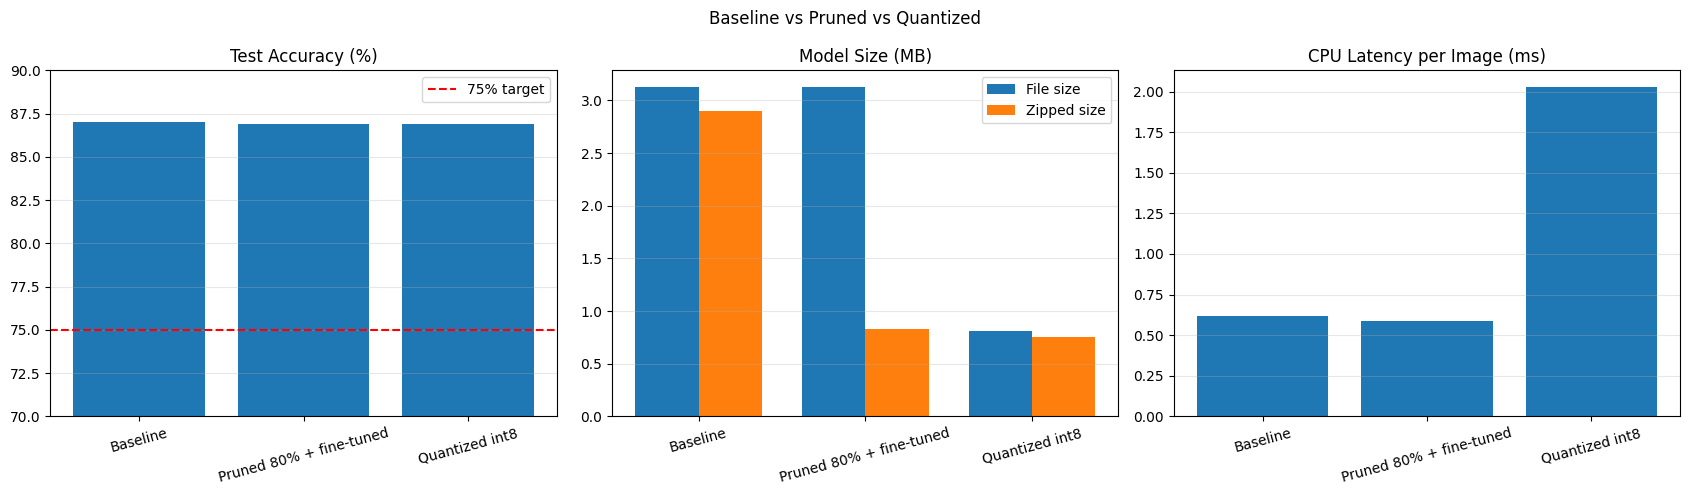

In [50]:
# Three charts side by side: accuracy, size and latency
models = comparison.index.tolist()
x = np.arange(len(models))
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Accuracy, with the 75% target line
axes[0].bar(x, comparison["Test accuracy (%)"])
axes[0].axhline(75, color="red", linestyle="--", label="75% target")
axes[0].set_ylim(70, 90)
axes[0].set_title("Test Accuracy (%)")
axes[0].legend()

# Size: normal file and zipped file next to each other
width = 0.38
axes[1].bar(x - width / 2, comparison["Size (MB)"], width, label="File size")
axes[1].bar(x + width / 2, comparison["Zipped size (MB)"], width, label="Zipped size")
axes[1].set_title("Model Size (MB)")
axes[1].legend()

# Latency on the CPU, one image at a time
axes[2].bar(x, comparison["CPU latency (ms)"])
axes[2].set_title("CPU Latency per Image (ms)")

for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(models, rotation=15)
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("Baseline vs Pruned vs Quantized")
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=150)
plt.show()

**Interpretation**

The table and charts compare the baseline with the two compressed models on the same test set and the same processor. All three models are well above the 75% target, and their accuracies are almost identical: 86.99% for the baseline, 86.91% for the pruned model and 86.92% for the quantized model. Note that the accuracy chart starts at 70% so that small differences are visible; on a full 0 to 100 scale the three bars would look equal.

Quantization gave the best result for size. It kept the accuracy almost exactly (a loss of only 0.07 points) and made the model 3.86 times smaller, from 3.13 MB to 0.81 MB, without any retraining. Its weakness was speed: on my processor it took 2.03 ms per image, only 0.31 times the speed of the baseline.

Pruning removed 80% of the weights and lost only 0.08 points of accuracy after fine-tuning. Its normal file size did not change at all, because the removed weights are still stored as zeros. The benefit appears only when the file is compressed: the zipped pruned model is 0.83 MB against 2.90 MB for the zipped baseline. Its speed was about the same as the baseline, since the processor still calculates with every zero.

Together the results show that compression has more than one meaning. Pruning reduced the number of useful weights, quantization reduced the storage per weight, and neither one made the model faster on my hardware for single images. Which technique is better depends on the goal. If the goal is a small download or a small file on a device, quantization is the clear choice here. If the goal is speed, neither technique helped in my set-up, and it would need structured pruning, a different quantization engine, or hardware designed for these techniques.

## Conclusion

In this assignment I built a convolutional neural network for the CIFAR-10 dataset and then applied two model compression techniques, pruning and quantization, to see what each one gains and what it costs.

The baseline CNN has 815,018 parameters. After 30 epochs of training on my graphics card, which took 5.4 minutes, it reached 86.99% accuracy on the test set, well above the 75% target. Its saved file is 3.13 MB and it takes 0.62 ms to classify one image on my processor. Most of its mistakes were between similar-looking classes, especially cats and dogs.

For pruning, I first tested how much of the model could be removed and found that accuracy collapsed above 70% without retraining. I then pruned 80% of the weights and fine-tuned for 10 epochs, which brought the test accuracy back to 86.91%, only 0.08 points below the baseline. However, the normal file size and the speed did not change, because the removed weights are still stored and calculated as zeros. The benefit only showed when the file was compressed: 0.83 MB zipped instead of 2.90 MB.

For quantization, I converted the weights and calculations from 32-bit to 8-bit numbers. The accuracy stayed almost the same at 86.92%, and the file became 3.86 times smaller at 0.81 MB, with no retraining at all. The main drawback was speed: for single images, the quantized model was about three times slower on my processor, because the fixed costs of converting to and from 8-bit outweighed the savings for such a small model.

My main lessons are that compression does not always mean faster, and that the results depend heavily on the hardware and software used. Pruning showed that the baseline had far more weights than it needed, and quantization was the most practical way to make the model smaller. For deploying this model to a phone or small device, I would choose quantization for its size reduction with almost no accuracy loss, and test the speed on the actual target device. To also gain speed, the next steps would be structured pruning, which removes whole filters so the layers become smaller, or combining pruning with quantization on hardware that supports them.